# ROWS

In [1]:
import numpy as np
import math
import csv
import pandas as pd
import matplotlib.pyplot as plt
import os

from EOS_functions import EOS_rock, EOS_core, EOS_core_mixed
from values import *
from Help_functions import get_Tmelt_MO, get_Tmelt_core, get_Tmelt_water, getphase
from water import getWater


def temp_pla2(T_e, R_e, a):
    t_p=T_e*(R_e/(2*a))**(1/2)
    return t_p

# Units: 1, kg, kg, km, km, dimensionless 
def pressao(P_t, M_p, M_t, R_p, R_t, tipo): 
    if tipo == 1: #Mercury
        beta = 1.05*10**(-13)
    elif tipo == 0:#Venus
        beta = 108.27
    elif tipo == 2:#marte
        beta = 0.0467
    elif tipo==3 or tipo==4 : #Earth
        beta = 1.014
    else:#Any other type, I'll disregard those anyway.
        beta=1
    P=beta*((M_p/M_t)**2)*((R_t/R_p)**4)*P_t
    return P*101325



def interior_structure(M,x_Fe_tot,x_H2O_tot, t, P):
  '''
  input:
   M: Mass in Earth masses
   x_Fe_tot: Iron weigth fraction in percent of the entire planet (core + mantle)
   x_H2O_tot: Water weigth fraction in percent of surface water/ice layer
  return:
   Rp_E - planet radius in Earth radii
   MOI - moment of inertia factor
   radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu - profiles of different planetary properties
   mat - material layers (<0 ices, 0 water, >0 different rock and core layers)
  '''

  '''Set initialization parameters'''
  Dcr = 50e3      # thickness of crustal layer in m
  Dlid = 300e3    # thickness of lithosphere, only used to set upper mantle temperature
  Psurf = P     # atmospheric surface pressure
  Tsurf = t     # potential surface temperature in K
  Tlid = 0.0    #2000 # in K; if set to 0, then mantle melt temp is used at Dlid depth to set Tlid
  DTcmb = -1.0  #1500 # in K, T jump at CMB; if set to neg value (e.g. -1), then jump is calculated via melt temp times -DTcmb
  nr = 500         # radial resolution from center of planet to surface
  tol = 0.001     # Convergence parameter
  maxIter = 20   # max number iterations

  # light elements in the core -> array added for molar fractions Si,C,S,O; e.g. (0.2 S -> Fe0.8S0.2), means weight fraction of 12 wt-% S
  xelem = np.array([0.0,0.0,0.2,0.0]) # initial core-averaged value
  xelem_ic = np.array([0.00,0.00,0.07,0.00]) # fixed inner core value (no real partitioning included yet; outer core value calculated during inner core growth

  X_FeM_mol = 0.1 # iron number in mantle (ratio of Fe-bearing molecules divided by Mg- and Fe-bearing molecules)
  X_H2OM = 0      # water content in mantle in wt-%, only used for el cond profile versions 2-4
  ec_model = 1    # electrical conductivity profiles: 1 - Xu, 2 - mat-dep prof without Fe, 3 - as 2 but with Fe dependence, 4 - as 3 but newer parameters


  '''Distribute iron between core and mantle'''

  x_Fe_tot = x_Fe_tot/100 # weight fraction instead of percent
  x_H2O_tot = x_H2O_tot/100
  M = M * 5.972*10**24 # mass in kg
  Mw = M*x_H2O_tot 
  G = 6.67384*10**(-11) # gravitational constant in m^3 / (kg s^2)

  # Molar masses:
  mMg=24.305; mFe=55.845; mSi=28.0855; mO=15.9994

  XmFe = 2*X_FeM_mol*mFe/(X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) # mantle mass fraction of iron w.r.t. mantle mass

  
  x_Fe = ( x_Fe_tot*M - XmFe*(M-Mw) ) / (M*(1-XmFe)) # core mass fraction w.r.t. total planet mass
  Mc = x_Fe*M
  if Mc<0.0:
      raise ValueError(f"Not enough iron in planet to have {iron_number} as iron number")
      Mc = 0.0
      x_Fe = 0.0
      XmFe = x_Fe_tot*M / (M-Mw) # adapt XmFe such that all iron is in mantle

      #XmFe * (X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) = 2*X_FeM_mol*mFe
      X_FeM_mol = XmFe*(2*mMg+mSi+4*mO)/(2*mFe-2*(mFe-mMg)*XmFe) # adapt mantle iron number

  Mm = M - Mc - Mw

  '''Initialization routines'''

  rho_c = 11000 # guess for core density in kg/m^3
  rho_m = 4000 # guess for mantle density in kg/m^3
  rho_w = 1000 # guess for water density in kg/m^3
  cp_c = 800 # guess for core heat capacity in J/kg K
  cp_m = 1300 # guess for mantle heat capacity in J/kg K
  cp_w = 4200 # guess for water heat capacity in J/kg K
  alpha_c = 0.00001 # guess for core thermal expansion ceoff. in 1/K
  alpha_m = 0.000025 # guess for mantle thermal expansion ceoff. in 1/K
  alpha_w = 0.00007 # guess for water thermal expansion ceoff. in 1/K

  Rc = ( Mc*3.0 / (4.0*math.pi*rho_c) )**(1/3) # first guess core radius
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius
  Rp = ( Mw*3.0 / (4.0*math.pi*rho_w) + Rm**3 )**(1/3) # first guess planet radius

  # Define arrays
  dr = np.zeros(nr) # distance between radius points
  radius = np.zeros(nr) # vector of radii, first radius is dr
  pressure = np.zeros(nr)
  gravity = np.zeros(nr)
  temperature = np.zeros(nr)
  density = np.zeros(nr)
  alpha = np.zeros(nr)
  cp = np.zeros(nr)
  KT = np.zeros(nr)
  KS = np.zeros(nr)
  mu = np.zeros(nr)
  mass = np.zeros(nr)
  mat = np.zeros(nr)
  elcond = np.zeros(nr)

  # set number of grid points in the three layers (core/mantle/water) based on initial radii, to be kept constant throughout iteration
  nc = int(nr * Rc/Rp)
  if (x_H2O_tot==0):
    nm = nr - nc
    nw = 0
  else:
    nm = int(nr * Rm/Rp) - nc
    nw = nr - nm - nc

  # Initialization of arrays: surface values
  if Mw>0:
    density[nr-1] = rho_w
    alpha[nr-1] = alpha_w
    cp[nr-1] = cp_w
  elif Mm>0:
    density[nr-1] = rho_m
    alpha[nr-1] = alpha_m
    cp[nr-1] = cp_m
  else: # pure iron shell
    density[nr-1] = rho_c
    alpha[nr-1] = alpha_c
    cp[nr-1] = cp_c
    Rc = Rp

  # Initialization of arrays: interpolation over depth
  for i in range(0,nr):
    if i==0:
      r_prev = 0.0
    else:
      r_prev = radius[i-1]
    if i<nc:
      dr[i] = Rc/float(nc)
      density[i] = rho_c
      alpha[i] = alpha_c
      cp[i] = cp_c
    elif i<nc+nm:
      dr[i] = (Rm-Rc)/float(nm)
      density[i] = rho_m
      alpha[i] = alpha_m
      cp[i] = cp_m
    else:
      dr[i] = (Rp-Rm)/float(nw)
      density[i] = rho_w
      alpha[i] = alpha_w
      cp[i] = cp_w
    radius[i] = r_prev + dr[i]


  # pressure and temperature are interpolated from surface downwards
  # gravity has boundary condition 0 in center (and not at surface)
  pressure[nr-1] = Psurf # 1 bar surface pressure
  temperature[nr-1] = Tsurf # surface temperature
  gravity[nr-1] = G*M/Rp**2 # first guess surface gravity
  plid = Dlid*rho_m*gravity[nr-1] # first guess at plid, will be calculated below


  '''Start iteration to determine interior structure'''

  iter = 1
  Store_V_vec_old = []
  Rp_old = 0
  while (abs(Rp-Rp_old) > tol) and (iter < maxIter):
      # store old Rp value to determine convergence
      Rp_old = Rp

      # average values will be re-determined from material properties
      rho_c = 0; rho_m = 0; rho_w = 0; vol_c = 0; vol_m = 0; vol_w = 0

      # update vectors for radius, gravity, pressure and temperature
      for i in range(0,nr):
        if i==0:
          r_prev = 0.0
        else:
          r_prev = radius[i-1]
        if i<nc:
          dr[i] = Rc/float(nc)
        elif i<nc+nm:
          dr[i] = (Rm-Rc)/float(nm)
        else:
          dr[i] = (Rp-Rm)/float(nw)
        radius[i] = r_prev + dr[i]

      
      gravity[0] = radius[0] * 4/3*math.pi*G*density[0]
      for i in range(1,nr):
          gravity[i] = gravity[i-1] + dr[i-1] * (4*math.pi*G*density[i-1] - 2*gravity[i-1]/radius[i-1])

      for i in range(nr-2,-1,-1):
          pressure[i] = pressure[i+1] + dr[i]*gravity[i]*density[i]
          if i>=nc+nm: # ocean layer, we assume here adiabatic profile from the surface
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          elif Rm-radius[i]<Dlid: # in lithosphere
              if Mw>0:
                Ts = temperature[nc+nm]
              else:
                Ts = Tsurf
              if Tlid>0:
                  
                  temperature[i] = Ts + (Tlid-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
              else:
                  temperature[i] = Ts + (get_Tmelt_MO(plid)-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
          elif Rm-radius[i+1]<Dlid: # first grid point in mantle
              if Tlid>0:
                  temperature[i] = Tlid 
              else:
                  temperature[i] = get_Tmelt_MO(plid) 
              plid = pressure[i] 
          elif (i+1==nc):
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
              if DTcmb >= 0:
                  
                  temperature[i] = temperature[i] + DTcmb
              else:
                  
                  temperature[i] = temperature[i] + (get_Tmelt_MO(pressure[i])-temperature[i]) * abs(DTcmb)
          else: 
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          
      Store_V_vec = []
      ric = 0
      for i in range(nr): # from center to surface
          # get correct layer depending on core size, mantle phase transitions, and crust thickness
          # 7 layers in total: 6-core, 5-ppv, 4-pv, 3-ri, 2-wa, 1-ol, 0-cr
          if i < nc:
              # iron core
              if temperature[i]<get_Tmelt_core(pressure[i]):
                mat[i] = 8 # inner core
                ric = radius[i] # updated until outer core is reached
              else:
                mat[i] = 7 # outer core
              arr_species = ['fehcp']
              mole_vec = [1]
          elif i >= nc+nm:
              # water layer
              mat[i] = 0 # liquid water or water ice, phase defined below
              arr_species = ['h2o']
              [Tm,phase] = get_Tmelt_water(pressure[i])
              if temperature[i]<Tm:
                mat[i] = -phase # ice phases stored with negative values
              mole_vec = [1]
          elif pressure[i] >= (127 + 0.006*(temperature[i]-2840))*10**9:
              # post-perovskite
              mat[i] = 6
              arr_species = ['mppv', 'fppv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif pressure[i] >= (22.9 - 0.0025*(temperature[i]-2260))*10**9:
              # perovskite
              mat[i] = 5
              arr_species = ['mgpv', 'fepv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif (pressure[i] >= (6.2 + 16.7*(1-X_FeM_mol) + 0.005*(temperature[i]-2260))*10**9) & (radius[i] <= Rm-Dcr):
              # ringwoodite
              mat[i] = 4
              arr_species = ['mgri', 'feri']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif (pressure[i] >= (4.92 + 5.4*(1-X_FeM_mol) + 0.0025*temperature[i])*10**9) & (radius[i] <= Rm-Dcr):
              # wadsleyite
              mat[i] = 3
              arr_species = ['mgwa', 'fewa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif radius[i] <= Rm-Dcr:
              # olivine
              mat[i] = 2
              arr_species = ['fo', 'fa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          else:
              # crust
              mat[i] = 1
              arr_species = ['an','di','qtz'] #Anorthite Feldspar Ca[Al2Si2]O8; Diopside CaMgSi2O6; Quartz SiO2
              mole_vec = [0.5, 0.25, 0.25]

          # mole fraction to mass fraction
          molmass = np.zeros(len(mole_vec))
          for k,species in enumerate(arr_species):
              res = values(species) # params for species
              molmass[k] = res.M
          mf_vec = mole_vec*molmass / np.sum(mole_vec*molmass)


         
          if mat[i] >= 7:
              if mat[i] == 8:
                xelemc = xelem_ic
              else:
                xelemc = (xelem * radius[nc-1]**3 - xelem_ic*ric**3)/(radius[nc-1]**3-ric**3) 
              
              cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_core_mixed(pressure[i]/10**9,temperature[i],xC=xelemc[1], xSi=xelemc[0], xS=xelemc[2], xO=xelemc[3])

          else:
              if Store_V_vec_old == []:
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec)
              else:
                 
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec,Store_V_vec_old[i])
          Store_V_vec.append(V_vec)

          # check profiles
          # update mass vector (used here only for visualization)
          if i==0:
              mass[i] = 4*math.pi*radius[i]**3*density[i]
          else:
              mass[i] = mass[i-1] + (radius[i]-radius[i-1])*4*math.pi*radius[i]**2*density[i]

          #Get new average densities for radius update
          if i==0:
              vol = 4/3 * math.pi * radius[i]**3
          else:
              vol = 4/3 * math.pi * (radius[i]**3 - radius[i-1]**3)

          if i <= nc:
              rho_c = rho_c + density[i]*vol
              vol_c = vol_c + vol
          elif i <= nc+nm:
              rho_m = rho_m + density[i]*vol
              vol_m = vol_m + vol
          else:
              rho_w = rho_w + density[i]*vol
              vol_w = vol_w + vol

      # Error with surface density for iron incl. light species
      if density[nr-1] < 0:
          density[nr-1] = density[nr-2]

      Store_V_vec_old = Store_V_vec

      if vol_c==0:
          vol_c=1 # in case that no core exists
      if vol_m==0:
          vol_m=1 # in case that no mantle exists
      if vol_w==0:
          vol_w=1 # in case that no water layer exists

      rho_c = rho_c / vol_c
      rho_m = rho_m / vol_m
      rho_w = rho_w / vol_w

      # update radius for core and mantle
      if Mc==0:
        Rc = 0
      else:
        Rc = (3*Mc/(4*math.pi*rho_c))**(1/3)
      if Mm==0:
        Rm = Rc
      else:
        if (rho_m>0.0):
          Rm = (Rc**3 + 3*Mm/(4*math.pi*rho_m))**(1/3)
        else:
          Rm = Rc
      if Mw==0:
        Rp = Rm
      else:
        if (rho_w>0.0): # can happen if surface water layer is smaller than resolution between two uppermost grid points
          Rp = (Rm**3 + 3*Mw/(4*math.pi*rho_w))**(1/3)
        else:
          Rp = Rm

      #print('{0:2d} {1:8.2f} {2:8.2f} {3:7.1f} {4:7.1f}'.format(iter,Rp/1000,Rc/1000,rho_m,rho_c))

      iter=iter+1


  '''Post-processing'''

  # Additional properties computed from final iteration (i.e. without influence on interior structure)

  # seismic velocity profiles
  vP = np.sqrt((KS*10**9+4/3*mu*10**9)/density)*10**-3 # in km/s
  vS = np.sqrt(mu*10**9/density)*10**-3 # in km/s

  # electrical conductivity
  kB = 8.61733e-5
  for i in range(nr):
      T = temperature[i]

      if mat[i]<=0:
          elcond[i] = 1.0e-20
      elif mat[i]<=2: # olivine layer and crust
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.69*math.exp(-1.62/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**2.98*X_FeM_mol*math.exp(-(1.71-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==3): # wadsleyite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**3.29*math.exp(-1.29/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 399.0*math.exp(-1.49/(kB*T)) \
              + 7.74*X_H2OM*math.exp(-(0.68-0.02*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.46*X_FeM_mol*math.exp(-(1.45-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.4*X_H2OM*math.exp(-(0.83-0.2*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==4): # ringwoodite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.92*math.exp(-1.16/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 838.0*math.exp(-1.36/(kB*T)) \
              + 27.7*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          elif ec_model==3:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with enthalpy and alpha from Yoshino&Katsura 2009
              elcond[i] = 10042*X_FeM_mol*math.exp(-(2.48-2.25*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.92*X_FeM_mol*math.exp(-(1.36-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==5) or (mat[i]==6): # pv or ppv layer
          #  Xu 2000 lower mantle values (for pv, use here the same formula for ppv)
          elcond[i] = 0.6851*10**1.12*math.exp(-0.62/(kB*T)) \
                    + 0.3149*10**2.69*math.exp(-0.85/(kB*T))
      else: # profile not calculated for core, does not matter anyway for induction heating
          elcond[i] = math.nan

  # log10 values; in iron core ec=nan -> log profile is also nan
  elcond = np.log10(elcond)

  # moment of inertia factor

  IntVal = 0
  for i in range(nr):
    IntVal += density[i] * (radius[i]-0.5*dr[i])**4 * dr[i]

  MOI = IntVal * 8*math.pi/(3*M*Rp**2)

  # radius in Earth radii instead of m
  Rc_E = Rc / 6371000
  Rp_E = Rp / 6371000
  Rm_E = Rm / 6371000

  return Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat


def visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(2,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")


  for i in range(2):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

from astropy import constants as const
from astropy import units as u

# Constantes
r_s = const.R_sun.to(u.au).value.item() #UA
m_s= const.M_sun.to(u.kg).value.item() #kg
T_sol=5772 #K
M_t= const.M_earth.to(u.kg).value.item() #kg
R_t= const.R_earth.to(u.km).value.item() #km
P_t= 1 #atm
UA=1.496e+11#m
R_sol=6.96*10**8 #m

In [2]:
import os, glob
print(os.getcwd())            # onde ele está procurando
print(glob.glob("*PREM*"))    # se aparecer [], o arquivo não está nessa pasta (ou o nome é outro)

C:\Users\vitor\0 ROWS_Interior-Structure-Model-main\ROWS_Interior-Structure-Model-main
['PREM500.csv']


In [3]:
PREM = np.loadtxt('PREM500.csv',delimiter=",") # doi:10.17611/DP/10131390

In [4]:
def visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(2,2, sharex=True,figsize=[12, 8.5])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  # add PREM values (radius,density,Vpv,Vsv,Q-kappa,Q-mu,Vph,Vsh,eta)

  ax[0,0].plot(PREM[:,0]/1000, PREM[:,1], ':', color='black', alpha=1, label="PREM")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")


  for i in range(2):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

# EXOPLEX

In [5]:
import sys
import io
import contextlib
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

EXOPLEX_DIR = os.path.expanduser("C:/Users/vitor/Downloads/ExoPlex-master/ExoPlex-master")
sys.path.insert(1, EXOPLEX_DIR)
os.chdir(os.path.join(EXOPLEX_DIR, 'Examples'))
os.makedirs('Data', exist_ok=True)

import ExoPlex as exo

FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07



# %% 4. UMA rodada do ExoPlex  (e o seu bloco 3, empacotado numa funcao)
comp_keys = ['wt_frac_water', 'FeMg', 'SiMg', 'CaMg', 'AlMg', 'wt_frac_FeO_wanted',
             'wt_frac_Si_core', 'wt_frac_O_core', 'wt_frac_S_core',
             'combine_phases', 'use_grids', 'conserve_oxy']
struct_keys = ['Pressure_range_mantle_UM', 'Temperature_range_mantle_UM', 'resolution_UM',
               'Pressure_range_mantle_LM', 'Temperature_range_mantle_LM', 'resolution_LM',
               'Mantle_potential_temp', 'water_potential_temp']


def get_planet(mass, water, feo, tpot, femg=FeMg):
    """Roda o ExoPlex e devolve o dicionario `Planet`."""
    n_w = number_h2o_layers if water > 0 else 0          # sem agua, sem camadas de agua
    layers = [num_mantle_layers, num_core_layers, n_w]   # ordem: [manto, nucleo, agua]
    comp = dict(zip(comp_keys, [water, femg, SiMg, CaMg, AlMg, feo, wt_frac_Si_core,
                                wt_frac_O_core, wt_frac_S_core, combine_phases,
                                use_grids, conserve_oxy]))
    struct = dict(zip(struct_keys, [Pressure_range_mantle_UM, Temperature_range_mantle_UM,
                                    resolution_UM, Pressure_range_mantle_LM,
                                    Temperature_range_mantle_LM, resolution_LM,
                                    tpot, water_potential_temp]))
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            filename = exo.functions.find_filename(comp, verbose)
            return exo.run_planet_mass(mass, comp, struct, layers, filename, verbose)
    except SystemExit:
        # o ExoPlex usa sys.exit() em alguns erros; vira erro comum para nao derrubar o kernel
        raise RuntimeError(" ".join(buf.getvalue().split()) or "sys.exit() dentro do ExoPlex")


@lru_cache(maxsize=None)                                  # nao repete combinacoes ja rodadas
def run_exoplex(mass, water, feo, tpot, femg=FeMg):
    P = get_planet(mass, water, feo, tpot, femg)
    nc = num_core_layers
    return dict(R=P['radius'][-1] / 6371e3,
                M=P['mass'][-1] / 5.97e24,
                CMF=P['mass'][nc] / P['mass'][-1],
                CRF=P['radius'][nc] / P['radius'][-1],
                P_cmb=P['pressure'][nc] / 1e4,            # bar -> GPa
                T_cmb=P['temperature'][nc])

# %% 9. GRAFICO DAS CAMADAS do melhor ajuste (seu bloco 5, em funcao)
def plot_structure(Planet, name, water, path=None, subdivide_mantle=True,
                   mantle_bounds_gpa=(120.0, 23.0, 13.5)):
    nc, nm = num_core_layers, num_mantle_layers
    n_w = number_h2o_layers if water > 0 else 0
    r = Planet['radius'] / 1e3
    P = Planet['pressure'] / 1e4
    i_cmb, i_wmb = nc, nc + nm
    r_top = r[i_wmb] if n_w > 0 else r[-1]
    zones = [(0, r[i_cmb], '#555555', 'Core')]
    if subdivide_mantle:
        # faixas de pressao APROXIMADAS (tipo-Terra; NAO vem do ExoPlex). Cada faixa mantem o
        # seu proprio rotulo, entao uma camada que nao existe (ex.: pPv num planeta pequeno)
        # simplesmente some em vez de deslocar os rotulos das outras.
        b1, b2, b3 = mantle_bounds_gpa
        bands = [(np.inf, b1, 'Lower mantle (pPv)', '#9b59b6'),
                 (b1, b2, 'Lower mantle (Bm)', '#c39bd3'),
                 (b2, b3, 'Transition zone', '#d5a56a'),
                 (b3, 0.0, 'Upper mantle', '#ffe14d')]
        P_m, r_m = P[i_cmb:i_wmb + 1][::-1], r[i_cmb:i_wmb + 1][::-1]     # P crescente p/ interp
        for p_hi, p_lo, lab, col in bands:
            x0 = r[i_cmb] if np.isinf(p_hi) else float(np.interp(p_hi, P_m, r_m))
            x1 = r_top if p_lo == 0 else float(np.interp(p_lo, P_m, r_m))
            if x1 - x0 > 1.0:                                               # > 1 km
                zones.append((x0, x1, col, lab))
    else:
        zones.append((r[i_cmb], r_top, '#c9a27a', 'Mantle'))
    if n_w > 0:
        zones.append((r[i_wmb], r[-1], '#4aa3df', 'Water / ice'))

    panels = [('Density', Planet['density'], 'Density in $kg/m^3$'),
              ('Pressure', P, 'Pressure in GPa'),
              ('Temperature', Planet['temperature'], 'Temperature in K'),
              ('Gravity', Planet['gravity'], 'Gravitational acceleration in $m/s^2$')]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)
    for ax, (title, y, ylabel) in zip(axes.ravel(), panels):
        for x0, x1, c, _ in zones:
            ax.axvspan(x0, x1, color=c, alpha=0.3, lw=0)
        ax.plot(r, y, 'k', lw=1.8)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
    for ax in axes[1]:
        ax.set_xlabel('Radius in km')
    fig.suptitle(f'Planetary Interior Structure of {name}', fontsize=18, fontweight='bold')
    handles = [mpatches.Patch(color=c, alpha=0.4, label=l) for _, _, c, l in zones]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    if path:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


# APLICAÇÃO DA COMPARAÇÃO ENTRE OS RESULTADOS DOS EXOPLANETAS

# 

# TERRA


1.0000 Earth masses with 38.50% iron leads to planet radius 0.9997 (6368 km) with MOI factor 0.330


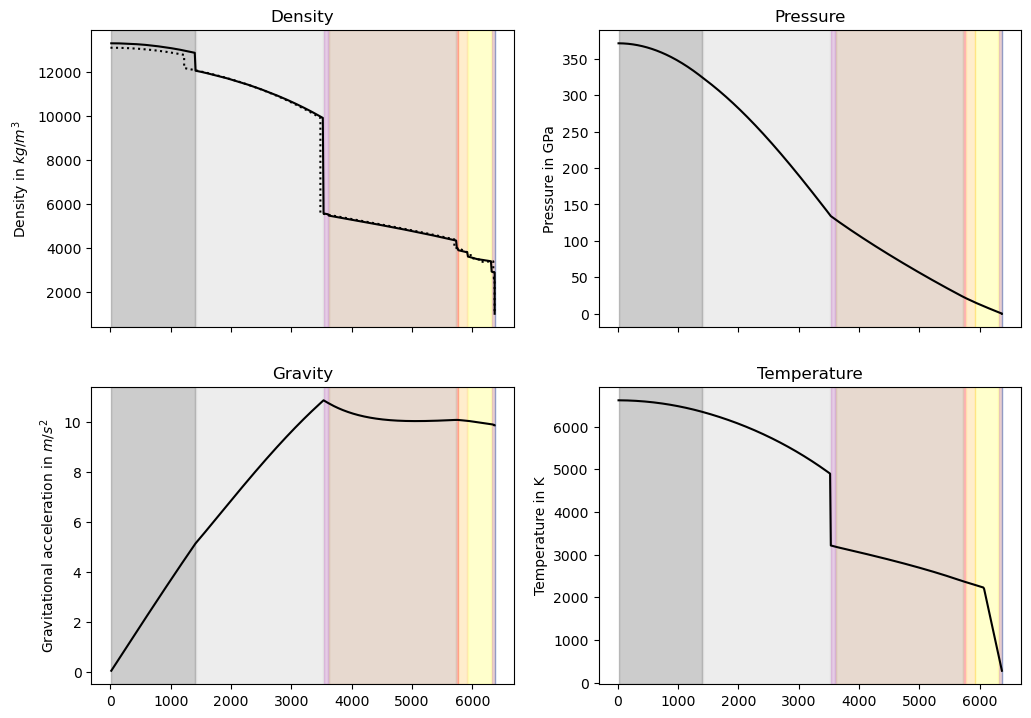

In [53]:
T_p=temp_pla2(T_sol, r_s, 1.0); P_p=pressao(P_t, M_t, M_t, R_t, R_t, 3)
M=1; x_Fe_tot=38.5; x_H2O_tot=0.1
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [54]:
NAME = 'Earth'
MASS = 1.0            
RADIUS = 1.0         
RADIUS_ERR = 0.001      
T_SURF = 288.0          
 
FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

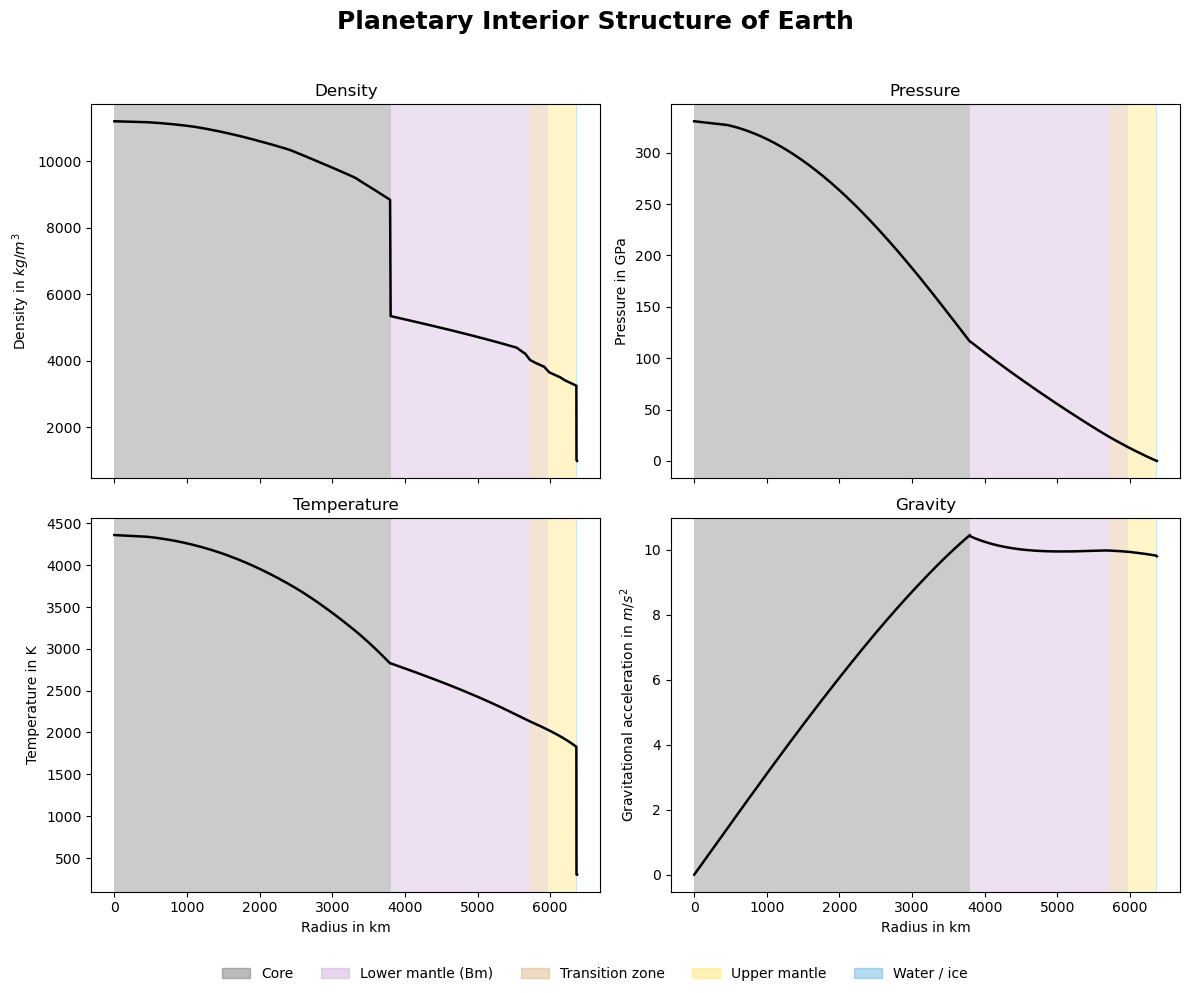

In [55]:
fe_exoplex=0.08; h2o_exoplex=0.08/100; t_pot=1820

Planet = get_planet(MASS, h2o_exoplex, fe_exoplex, t_pot)
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, h2o_exoplex, path=f"Data/{NAME.replace(' ', '_')}_structure.png")

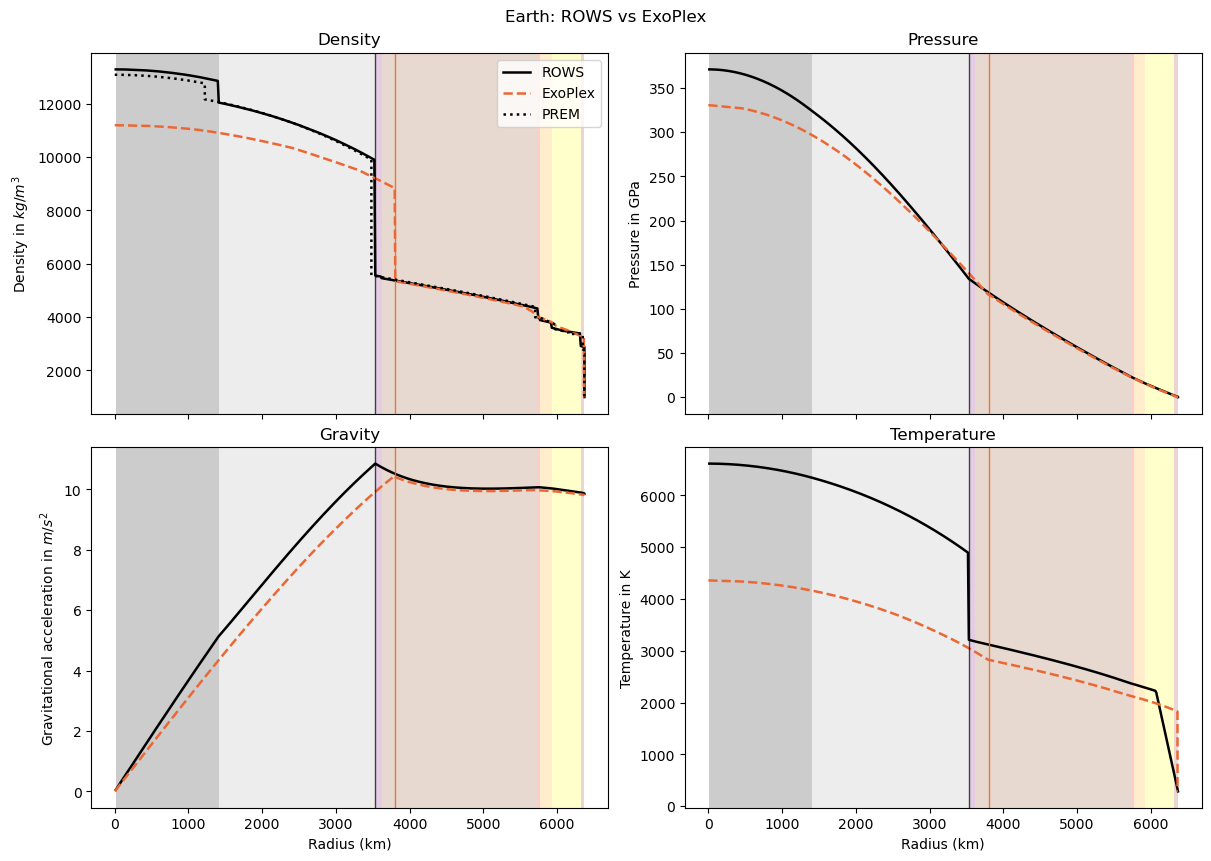

                                    ROWS     ExoPlex
Core radius (km)                    3533        3804
Nucleus radius / planet radius       0.555       0.597

Δ core radius (ExoPlex − ROWS) = +271 km (+7.7% of ROWS value)


In [56]:
mass_obs, temp_obs = MASS, T_SURF                       
FE_ROWS, H2O_ROWS = x_Fe_tot, x_H2O_tot         

(Rp_E, Rc_E, Rm_E, MOI, r_rows, rho_rows, g_rows, P_rows, T_rows,
 alpha, cp, m_rows, elcond, vP, vS, KT, KS, mu, mat) = \
    interior_structure(mass_obs, FE_ROWS, H2O_ROWS, temp_obs, P_p)

r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (np.asarray(a, float) for a in
                                                 (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))
if r_rows[0] > r_rows[-1]:            # garante centro -> superfície
    r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (a[::-1] for a in (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))


i_core = np.where((mat == 7) | (mat == 8))[0]
Rcore_rows = r_rows[min(i_core.max() + 1, len(r_rows) - 1)] if len(i_core) else 0.0


r_exo = np.asarray(Planet['radius'], float)
rho_exo = np.asarray(Planet['density'], float)
g_exo = np.asarray(Planet['gravity'], float)
P_exo = np.asarray(Planet['pressure'], float) * 1e5          # bar -> Pa
T_exo = np.asarray(Planet['temperature'], float)
ok = rho_exo > 0                                              # tira o ponto final com rho = 0
r_exo, rho_exo, g_exo, P_exo, T_exo = (a[ok] for a in (r_exo, rho_exo, g_exo, P_exo, T_exo))
Rcore_exo = np.asarray(Planet['radius'], float)[num_core_layers]   # 1º ponto do manto


km = 1e3
cor_exo = "#eb6834"
# camadas do ROWS (mesmas cores do seu gráfico original)
camadas = [(mat == 0, 'DodgerBlue', .5), (mat < 0, 'RoyalBlue', .2), (mat == 1, 'brown', .2),
           (mat == 2, 'yellow', .2), (mat == 3, 'orange', .2), (mat == 4, 'red', .2),
           (mat == 5, 'SaddleBrown', .2), (mat == 6, 'purple', .2),
           (mat == 7, 'darkgrey', .2), (mat == 8, 'black', .2)]

fig, ax = plt.subplots(2, 2, sharex=True, figsize=(12, 8.5), constrained_layout=True)
paineis = [(ax[0, 0], "Density", "Density in $kg/m^3$", rho_rows, rho_exo),
           (ax[0, 1], "Pressure", "Pressure in GPa", P_rows / 1e9, P_exo / 1e9),
           (ax[1, 0], "Gravity", "Gravitational acceleration in $m/s^2$", g_rows, g_exo),
           (ax[1, 1], "Temperature", "Temperature in K", T_rows, T_exo)]
for a, titulo, ylabel, y_r, y_e in paineis:
    for cond, cor, alfa in camadas:                       
        idx = np.where(cond)[0]
        if idx.size:
            a.axvspan(r_rows[idx[0]] / km, r_rows[min(idx[-1] + 1, len(r_rows) - 1)] / km,
                      alpha=alfa, color=cor, lw=0)
    a.plot(r_rows / km, y_r, color='black', lw=1.8, label="ROWS")
    a.plot(r_exo / km, y_e, color=cor_exo, lw=1.8, ls='--', label="ExoPlex")
    a.axvline(Rcore_rows / km, color='black', lw=1, alpha=.7)      # topo do núcleo
    a.axvline(Rcore_exo / km, color=cor_exo, lw=1, alpha=.9)
    a.set_title(titulo)
    a.set_ylabel(ylabel)
ax[0, 0].plot(PREM[:, 0] / km, PREM[:, 1], ':', color='black', lw=1.8, label="PREM")
ax[0, 0].legend(loc='upper right')
for a in ax[1]:
    a.set_xlabel("Radius (km)")
fig.suptitle(f"{NAME}: ROWS vs ExoPlex")
os.makedirs("Data", exist_ok=True)
fig.savefig(f"Data/{NAME.replace(' ', '_')}_ROWS_vs_ExoPlex.png", dpi=200)
plt.show()


dR = Rcore_exo - Rcore_rows
print(f"{'':28s}{'ROWS':>12s}{'ExoPlex':>12s}")
print(f"{'Core radius (km)':28s}{Rcore_rows / km:12.0f}{Rcore_exo / km:12.0f}")
print(f"{'Nucleus radius / planet radius':28s}{Rcore_rows / r_rows[-1]:12.3f}{Rcore_exo / r_exo[-1]:12.3f}")
print(f"\nΔ core radius (ExoPlex − ROWS) = {dR / km:+.0f} km ({100 * dR / Rcore_rows:+.1f}% of ROWS value)")

# Kepler-186 f


1.7100 Earth masses with 35.00% iron leads to planet radius 1.1719 (7466 km) with MOI factor 0.330


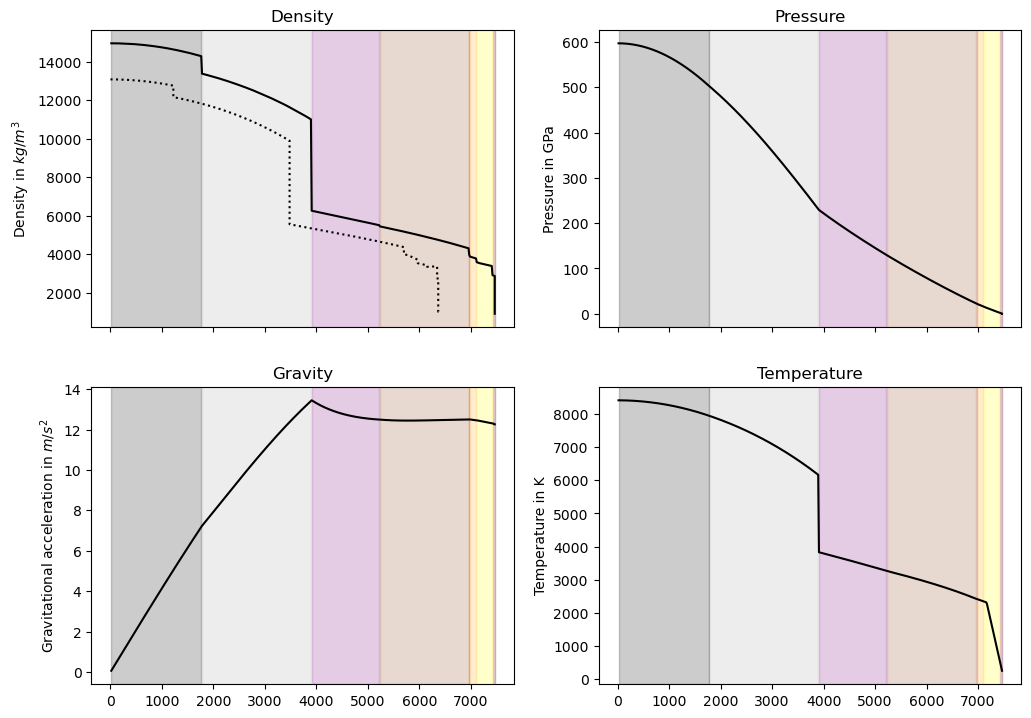

In [26]:
M=1.71; x_Fe_tot=35.0; x_H2O_tot=0.1; T_p=253; P_p=1.58*10**5
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [27]:
NAME = 'Kepler-186 f'
MASS = 1.71            
RADIUS = 1.17          
RADIUS_ERR = 0.08     
T_SURF =  253         

FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False


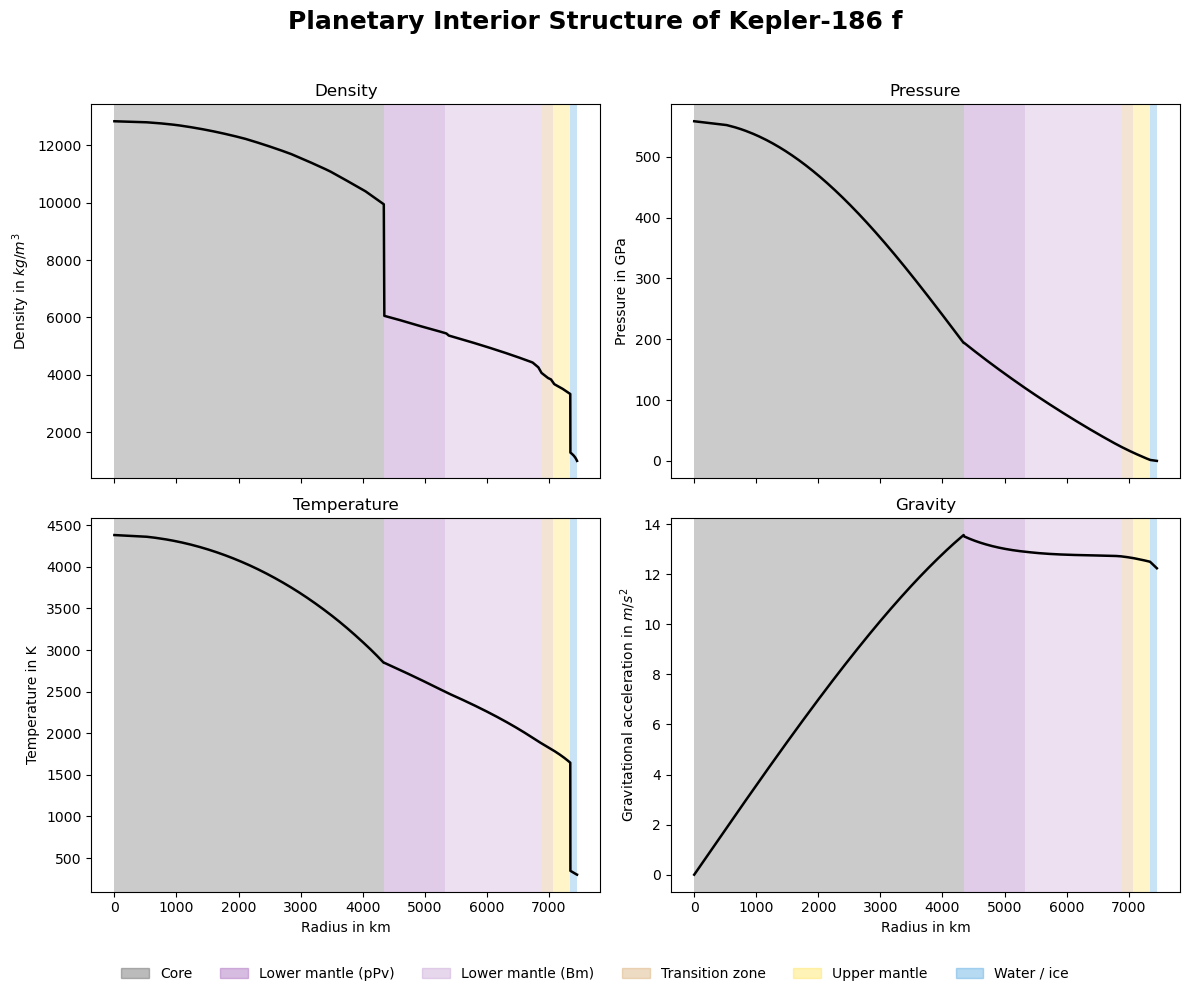

In [28]:
fe_exoplex=0.08; h2o_exoplex=0.86/100; t_pot=1633

Planet = get_planet(MASS, h2o_exoplex, fe_exoplex, t_pot)
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, h2o_exoplex, path=f"Data/{NAME.replace(' ', '_')}_structure.png")

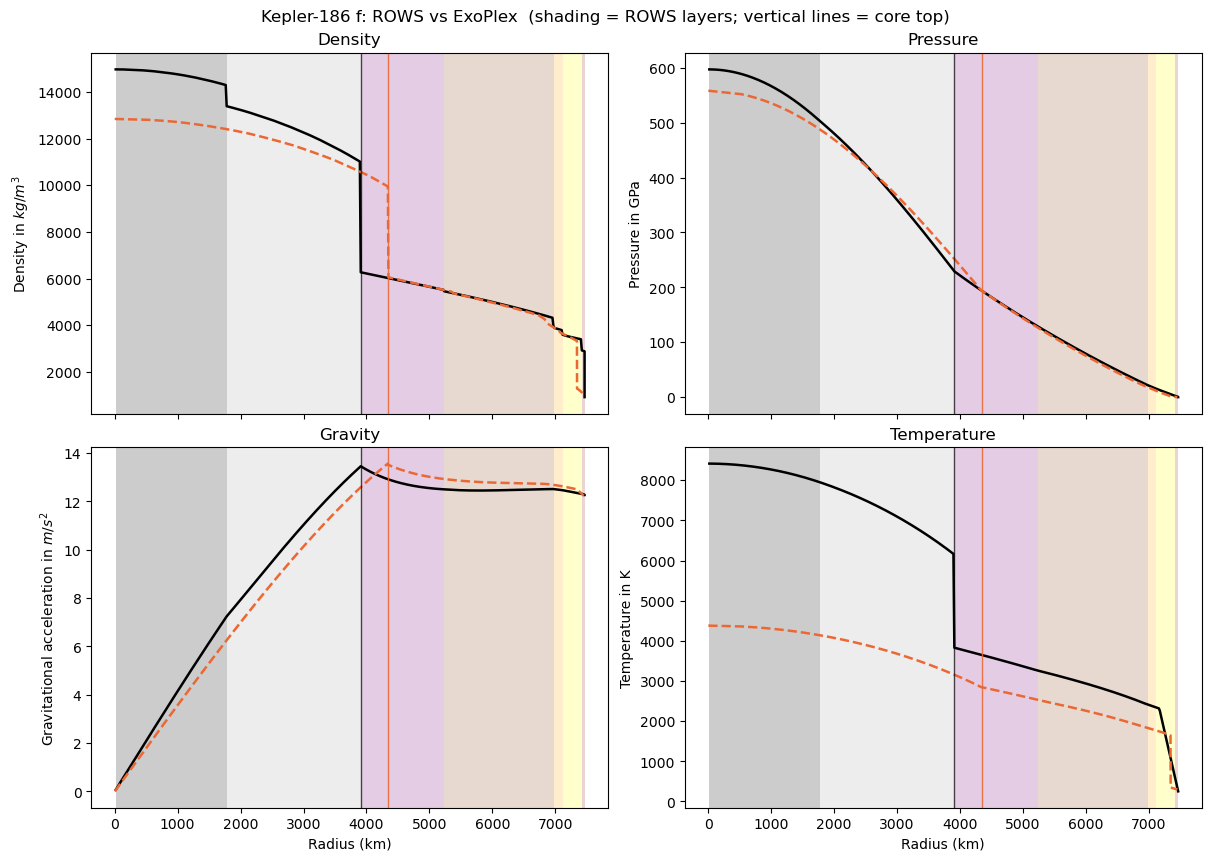

                                    ROWS     ExoPlex
Raio do núcleo (km)                 3910        4349
Raio núcleo / raio planeta         0.524       0.583

Δ raio do núcleo (ExoPlex − ROWS) = +440 km  (+11.3% do valor do ROWS)


In [29]:
mass_obs, temp_obs = MASS, T_SURF                       
FE_ROWS, H2O_ROWS = x_Fe_tot, x_H2O_tot         

(Rp_E, Rc_E, Rm_E, MOI, r_rows, rho_rows, g_rows, P_rows, T_rows,
 alpha, cp, m_rows, elcond, vP, vS, KT, KS, mu, mat) = \
    interior_structure(mass_obs, FE_ROWS, H2O_ROWS, temp_obs, P_p)

r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (np.asarray(a, float) for a in
                                                 (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))
if r_rows[0] > r_rows[-1]:            # garante centro -> superfície
    r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (a[::-1] for a in (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))

i_core = np.where((mat == 7) | (mat == 8))[0]
Rcore_rows = r_rows[min(i_core.max() + 1, len(r_rows) - 1)] if len(i_core) else 0.0


r_exo = np.asarray(Planet['radius'], float)
rho_exo = np.asarray(Planet['density'], float)
g_exo = np.asarray(Planet['gravity'], float)
P_exo = np.asarray(Planet['pressure'], float) * 1e5          
T_exo = np.asarray(Planet['temperature'], float)
ok = rho_exo > 0                                              
r_exo, rho_exo, g_exo, P_exo, T_exo = (a[ok] for a in (r_exo, rho_exo, g_exo, P_exo, T_exo))
Rcore_exo = np.asarray(Planet['radius'], float)[num_core_layers]   


km = 1e3
cor_exo = "#eb6834"

camadas = [(mat == 0, 'DodgerBlue', .5), (mat < 0, 'RoyalBlue', .2), (mat == 1, 'brown', .2),
           (mat == 2, 'yellow', .2), (mat == 3, 'orange', .2), (mat == 4, 'red', .2),
           (mat == 5, 'SaddleBrown', .2), (mat == 6, 'purple', .2),
           (mat == 7, 'darkgrey', .2), (mat == 8, 'black', .2)]

fig, ax = plt.subplots(2, 2, sharex=True, figsize=(12, 8.5), constrained_layout=True)
paineis = [(ax[0, 0], "Density", "Density in $kg/m^3$", rho_rows, rho_exo),
           (ax[0, 1], "Pressure", "Pressure in GPa", P_rows / 1e9, P_exo / 1e9),
           (ax[1, 0], "Gravity", "Gravitational acceleration in $m/s^2$", g_rows, g_exo),
           (ax[1, 1], "Temperature", "Temperature in K", T_rows, T_exo)]
for a, titulo, ylabel, y_r, y_e in paineis:
    for cond, cor, alfa in camadas:                       
        idx = np.where(cond)[0]
        if idx.size:
            a.axvspan(r_rows[idx[0]] / km, r_rows[min(idx[-1] + 1, len(r_rows) - 1)] / km,
                      alpha=alfa, color=cor, lw=0)
    a.plot(r_rows / km, y_r, color='black', lw=1.8, label="ROWS")
    a.plot(r_exo / km, y_e, color=cor_exo, lw=1.8, ls='--', label="ExoPlex")
    a.axvline(Rcore_rows / km, color='black', lw=1, alpha=.7)      o
    a.axvline(Rcore_exo / km, color=cor_exo, lw=1, alpha=.9)
    a.set_title(titulo)
    a.set_ylabel(ylabel)
for a in ax[1]:
    a.set_xlabel("Radius (km)")
fig.suptitle(f"{NAME}: ROWS vs ExoPlex  (shading = ROWS layers; vertical lines = core top)")
os.makedirs("Data", exist_ok=True)
fig.savefig(f"Data/{NAME.replace(' ', '_')}_ROWS_vs_ExoPlex.png", dpi=200)
plt.show()


dR = Rcore_exo - Rcore_rows
print(f"{'':28s}{'ROWS':>12s}{'ExoPlex':>12s}")
print(f"{'Raio do núcleo (km)':28s}{Rcore_rows / km:12.0f}{Rcore_exo / km:12.0f}")
print(f"{'Raio núcleo / raio planeta':28s}{Rcore_rows / r_rows[-1]:12.3f}{Rcore_exo / r_exo[-1]:12.3f}")
print(f"\nΔ raio do núcleo (ExoPlex − ROWS) = {dR / km:+.0f} km  ({100 * dR / Rcore_rows:+.1f}% do valor do ROWS)")

# TOI-700 e


0.8180 Earth masses with 34.50% iron leads to planet radius 0.9525 (6068 km) with MOI factor 0.335


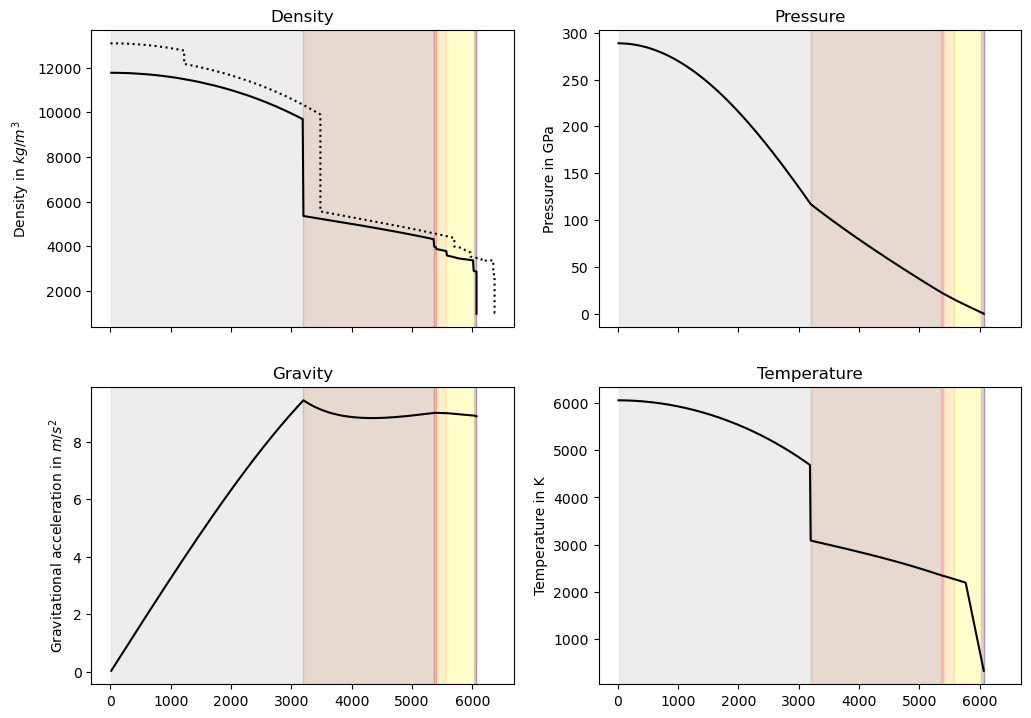

In [30]:
M=0.818; x_Fe_tot=34.50; x_H2O_tot=0.1; T_p=323; P_p=0.82*10**5
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)

print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [31]:
NAME = 'TOI-700 e'
MASS = 0.818            
RADIUS = 0.953          
RADIUS_ERR = 0.089     
T_SURF = 323.           
    
FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False

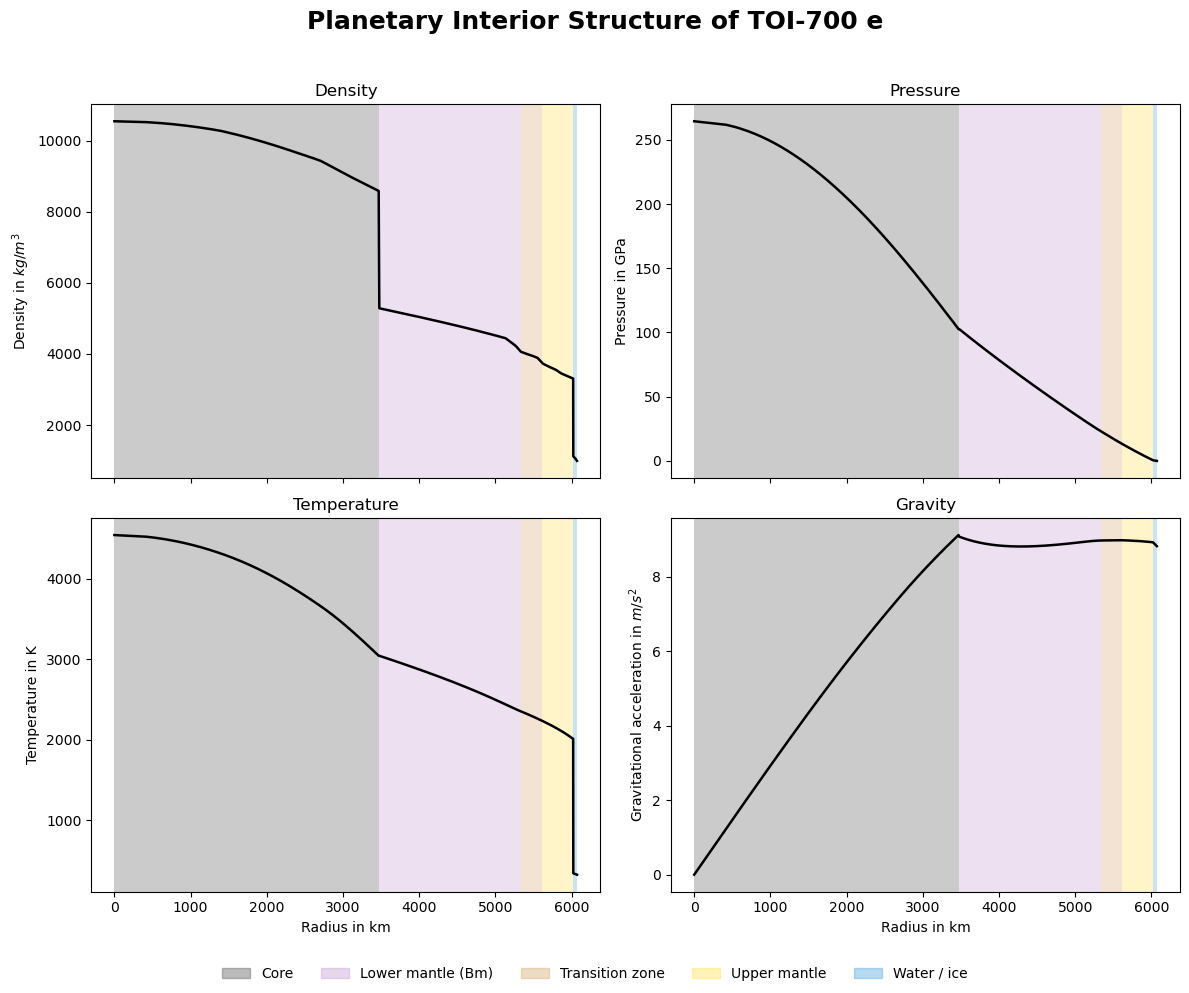

In [32]:
fe_exoplex=0.12; h2o_exoplex=0.51/100; t_pot=2000

Planet = get_planet(MASS, h2o_exoplex, fe_exoplex, t_pot)
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, h2o_exoplex, path=f"Data/{NAME.replace(' ', '_')}_structure.png")

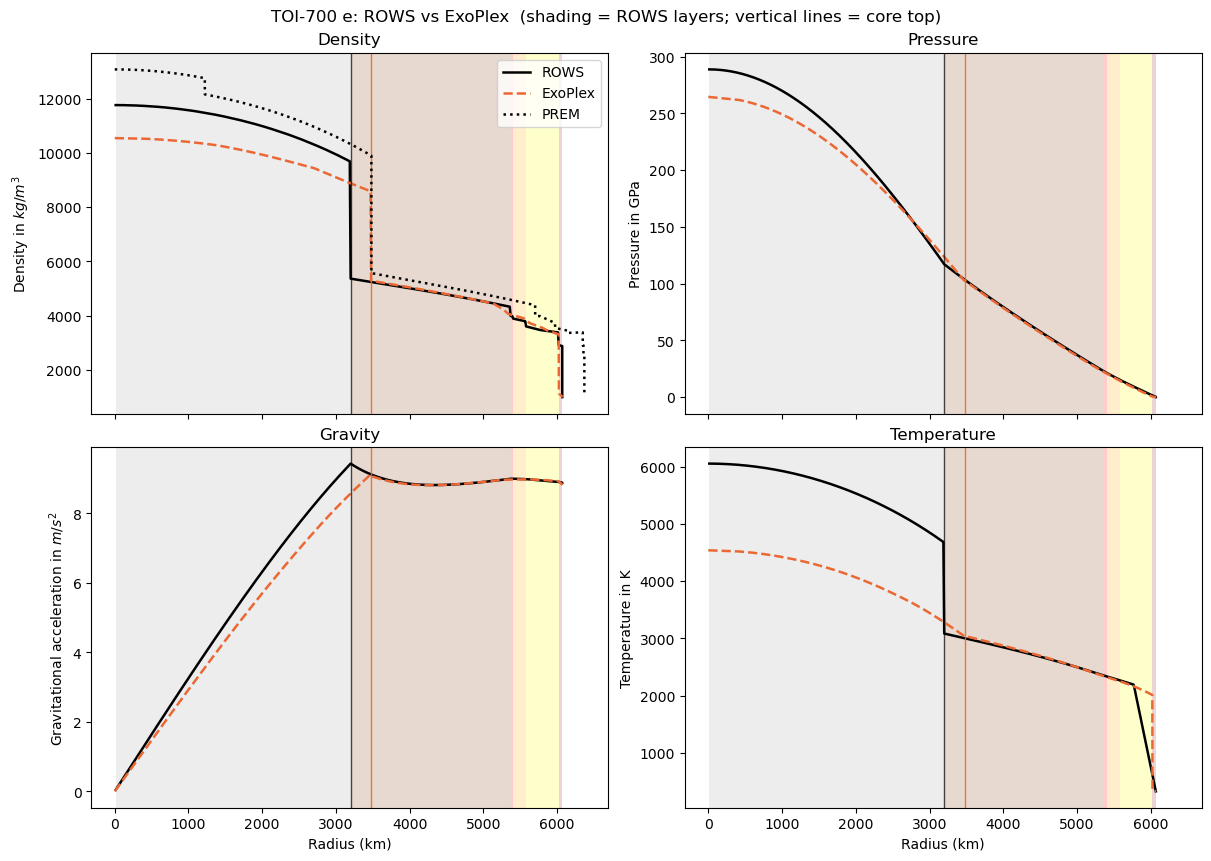

                                    ROWS     ExoPlex
Raio do núcleo (km)                 3199        3477
Raio núcleo / raio planeta         0.527       0.573

Δ raio do núcleo (ExoPlex − ROWS) = +278 km  (+8.7% do valor do ROWS)


In [33]:
mass_obs, temp_obs = MASS, T_SURF                       
FE_ROWS, H2O_ROWS = x_Fe_tot, x_H2O_tot         

(Rp_E, Rc_E, Rm_E, MOI, r_rows, rho_rows, g_rows, P_rows, T_rows,
 alpha, cp, m_rows, elcond, vP, vS, KT, KS, mu, mat) = \
    interior_structure(mass_obs, FE_ROWS, H2O_ROWS, temp_obs, P_p)

r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (np.asarray(a, float) for a in
                                                 (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))
if r_rows[0] > r_rows[-1]:            
    r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (a[::-1] for a in (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))


i_core = np.where((mat == 7) | (mat == 8))[0]
Rcore_rows = r_rows[min(i_core.max() + 1, len(r_rows) - 1)] if len(i_core) else 0.0


r_exo = np.asarray(Planet['radius'], float)
rho_exo = np.asarray(Planet['density'], float)
g_exo = np.asarray(Planet['gravity'], float)
P_exo = np.asarray(Planet['pressure'], float) * 1e5          
T_exo = np.asarray(Planet['temperature'], float)
ok = rho_exo > 0                                              
r_exo, rho_exo, g_exo, P_exo, T_exo = (a[ok] for a in (r_exo, rho_exo, g_exo, P_exo, T_exo))
Rcore_exo = np.asarray(Planet['radius'], float)[num_core_layers]   

km = 1e3
cor_exo = "#eb6834"

camadas = [(mat == 0, 'DodgerBlue', .5), (mat < 0, 'RoyalBlue', .2), (mat == 1, 'brown', .2),
           (mat == 2, 'yellow', .2), (mat == 3, 'orange', .2), (mat == 4, 'red', .2),
           (mat == 5, 'SaddleBrown', .2), (mat == 6, 'purple', .2),
           (mat == 7, 'darkgrey', .2), (mat == 8, 'black', .2)]

fig, ax = plt.subplots(2, 2, sharex=True, figsize=(12, 8.5), constrained_layout=True)
paineis = [(ax[0, 0], "Density", "Density in $kg/m^3$", rho_rows, rho_exo),
           (ax[0, 1], "Pressure", "Pressure in GPa", P_rows / 1e9, P_exo / 1e9),
           (ax[1, 0], "Gravity", "Gravitational acceleration in $m/s^2$", g_rows, g_exo),
           (ax[1, 1], "Temperature", "Temperature in K", T_rows, T_exo)]
for a, titulo, ylabel, y_r, y_e in paineis:
    for cond, cor, alfa in camadas:                       
        idx = np.where(cond)[0]
        if idx.size:
            a.axvspan(r_rows[idx[0]] / km, r_rows[min(idx[-1] + 1, len(r_rows) - 1)] / km,
                      alpha=alfa, color=cor, lw=0)
    a.plot(r_rows / km, y_r, color='black', lw=1.8, label="ROWS")
    a.plot(r_exo / km, y_e, color=cor_exo, lw=1.8, ls='--', label="ExoPlex")
    a.axvline(Rcore_rows / km, color='black', lw=1, alpha=.7)      
    a.axvline(Rcore_exo / km, color=cor_exo, lw=1, alpha=.9)
    a.set_title(titulo)
    a.set_ylabel(ylabel)
ax[0, 0].plot(PREM[:, 0] / km, PREM[:, 1], ':', color='black', lw=1.8, label="PREM")
ax[0, 0].legend(loc='upper right')
for a in ax[1]:
    a.set_xlabel("Radius (km)")
fig.suptitle(f"{NAME}: ROWS vs ExoPlex  (shading = ROWS layers; vertical lines = core top)")
os.makedirs("Data", exist_ok=True)
fig.savefig(f"Data/{NAME.replace(' ', '_')}_ROWS_vs_ExoPlex.png", dpi=200)
plt.show()

dR = Rcore_exo - Rcore_rows
print(f"{'':28s}{'ROWS':>12s}{'ExoPlex':>12s}")
print(f"{'Raio do núcleo (km)':28s}{Rcore_rows / km:12.0f}{Rcore_exo / km:12.0f}")
print(f"{'Raio núcleo / raio planeta':28s}{Rcore_rows / r_rows[-1]:12.3f}{Rcore_exo / r_exo[-1]:12.3f}")
print(f"\nΔ raio do núcleo (ExoPlex − ROWS) = {dR / km:+.0f} km  ({100 * dR / Rcore_rows:+.1f}% do valor do ROWS)")

# LHS 1140 b


5.6000 Earth masses with 17.50% iron leads to planet radius 1.7293 (11017 km) with MOI factor 0.324


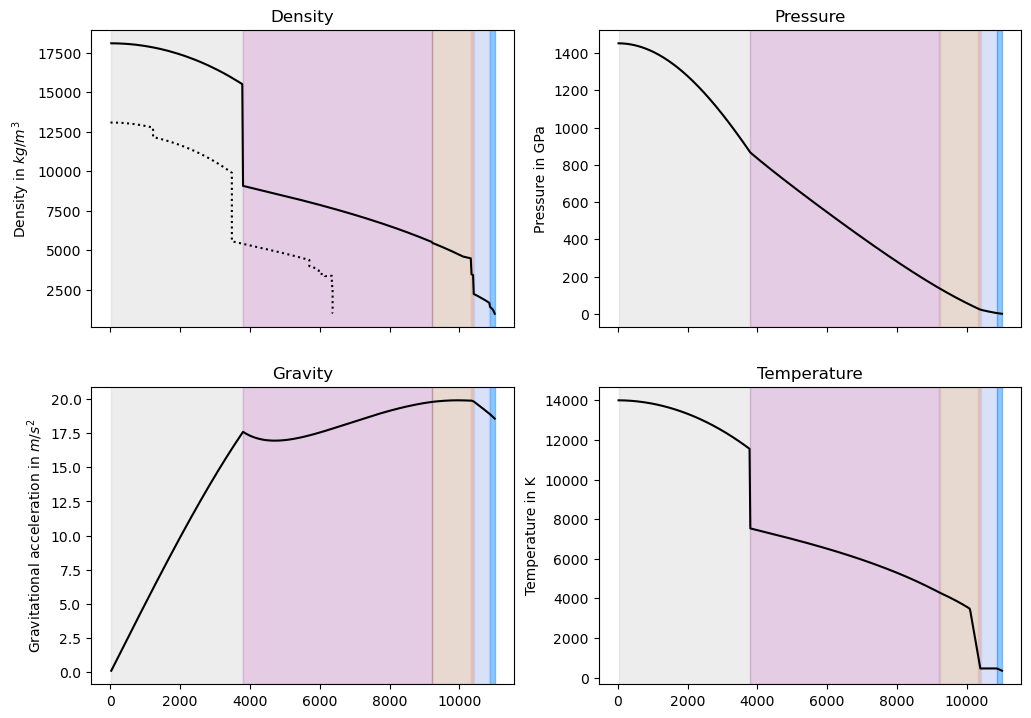

In [42]:
M=5.6; x_Fe_tot=17.50; x_H2O_tot=4.7; T_p=346; P_p=3.55*10**5
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [43]:
NAME = 'LHS-1140 b'
MASS = 5.6            
RADIUS = 1.73          
RADIUS_ERR = 0.025      
T_SURF = 346.          
    
FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False


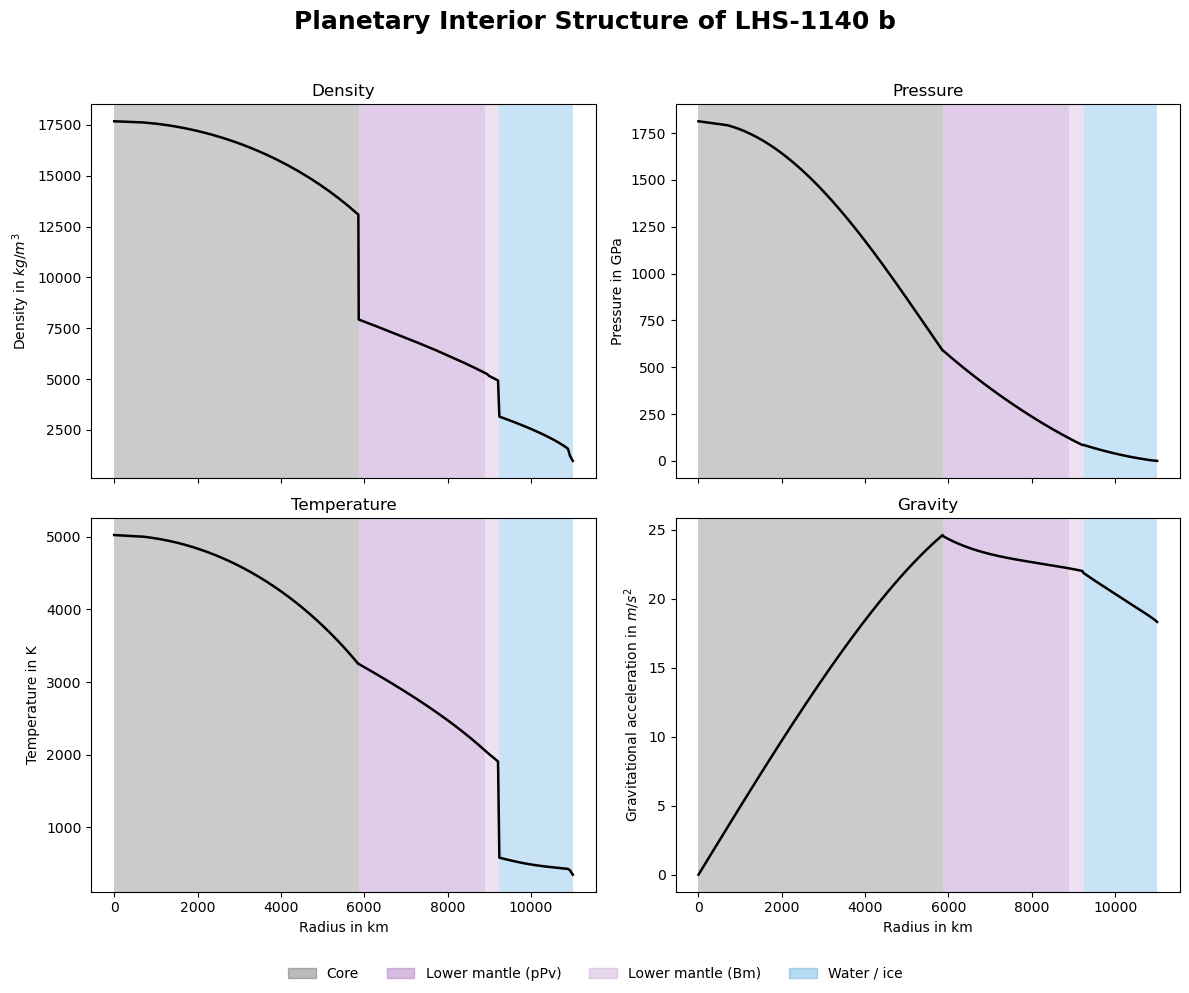

In [44]:
fe_exoplex=0.00; h2o_exoplex=16.11/100; t_pot=1650

Planet = get_planet(MASS, h2o_exoplex, fe_exoplex, t_pot)
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, h2o_exoplex, path=f"Data/{NAME.replace(' ', '_')}_structure.png")

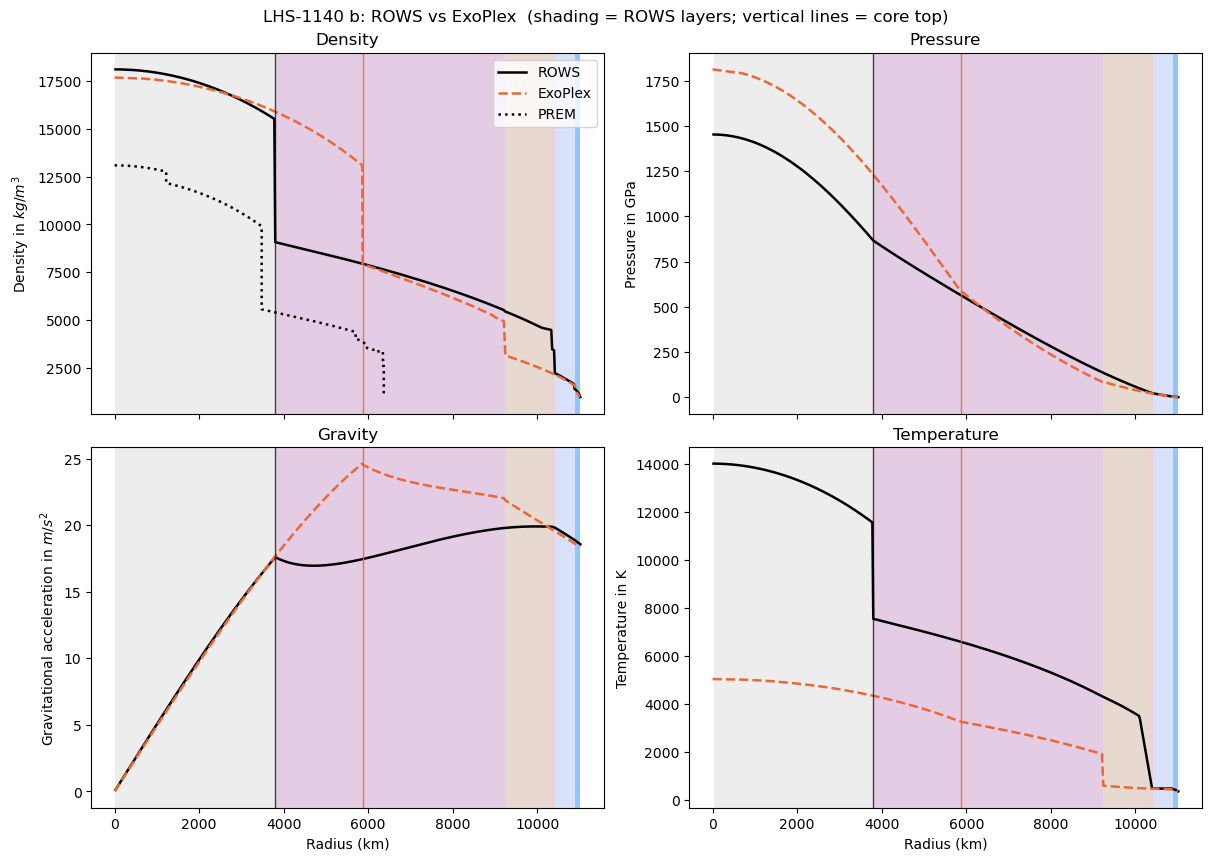

                                    ROWS     ExoPlex
Raio do núcleo (km)                 3801        5868
Raio núcleo / raio planeta         0.345       0.533

Δ raio do núcleo (ExoPlex − ROWS) = +2067 km  (+54.4% do valor do ROWS)


In [45]:
mass_obs, temp_obs = MASS, T_SURF                       
FE_ROWS, H2O_ROWS = x_Fe_tot, x_H2O_tot         

(Rp_E, Rc_E, Rm_E, MOI, r_rows, rho_rows, g_rows, P_rows, T_rows,
 alpha, cp, m_rows, elcond, vP, vS, KT, KS, mu, mat) = \
    interior_structure(mass_obs, FE_ROWS, H2O_ROWS, temp_obs, P_p)

r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (np.asarray(a, float) for a in
                                                 (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))
if r_rows[0] > r_rows[-1]:            
    r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (a[::-1] for a in (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))


i_core = np.where((mat == 7) | (mat == 8))[0]
Rcore_rows = r_rows[min(i_core.max() + 1, len(r_rows) - 1)] if len(i_core) else 0.0


r_exo = np.asarray(Planet['radius'], float)
rho_exo = np.asarray(Planet['density'], float)
g_exo = np.asarray(Planet['gravity'], float)
P_exo = np.asarray(Planet['pressure'], float) * 1e5          
T_exo = np.asarray(Planet['temperature'], float)
ok = rho_exo > 0                                             
r_exo, rho_exo, g_exo, P_exo, T_exo = (a[ok] for a in (r_exo, rho_exo, g_exo, P_exo, T_exo))
Rcore_exo = np.asarray(Planet['radius'], float)[num_core_layers]  


km = 1e3
cor_exo = "#eb6834"

camadas = [(mat == 0, 'DodgerBlue', .5), (mat < 0, 'RoyalBlue', .2), (mat == 1, 'brown', .2),
           (mat == 2, 'yellow', .2), (mat == 3, 'orange', .2), (mat == 4, 'red', .2),
           (mat == 5, 'SaddleBrown', .2), (mat == 6, 'purple', .2),
           (mat == 7, 'darkgrey', .2), (mat == 8, 'black', .2)]

fig, ax = plt.subplots(2, 2, sharex=True, figsize=(12, 8.5), constrained_layout=True)
paineis = [(ax[0, 0], "Density", "Density in $kg/m^3$", rho_rows, rho_exo),
           (ax[0, 1], "Pressure", "Pressure in GPa", P_rows / 1e9, P_exo / 1e9),
           (ax[1, 0], "Gravity", "Gravitational acceleration in $m/s^2$", g_rows, g_exo),
           (ax[1, 1], "Temperature", "Temperature in K", T_rows, T_exo)]
for a, titulo, ylabel, y_r, y_e in paineis:
    for cond, cor, alfa in camadas:                       
        idx = np.where(cond)[0]
        if idx.size:
            a.axvspan(r_rows[idx[0]] / km, r_rows[min(idx[-1] + 1, len(r_rows) - 1)] / km,
                      alpha=alfa, color=cor, lw=0)
    a.plot(r_rows / km, y_r, color='black', lw=1.8, label="ROWS")
    a.plot(r_exo / km, y_e, color=cor_exo, lw=1.8, ls='--', label="ExoPlex")
    a.axvline(Rcore_rows / km, color='black', lw=1, alpha=.7)      
    a.axvline(Rcore_exo / km, color=cor_exo, lw=1, alpha=.9)
    a.set_title(titulo)
    a.set_ylabel(ylabel)
ax[0, 0].plot(PREM[:, 0] / km, PREM[:, 1], ':', color='black', lw=1.8, label="PREM")
ax[0, 0].legend(loc='upper right')
for a in ax[1]:
    a.set_xlabel("Radius (km)")
fig.suptitle(f"{NAME}: ROWS vs ExoPlex  (shading = ROWS layers; vertical lines = core top)")
os.makedirs("Data", exist_ok=True)
fig.savefig(f"Data/{NAME.replace(' ', '_')}_ROWS_vs_ExoPlex.png", dpi=200)
plt.show()


dR = Rcore_exo - Rcore_rows
print(f"{'':28s}{'ROWS':>12s}{'ExoPlex':>12s}")
print(f"{'Raio do núcleo (km)':28s}{Rcore_rows / km:12.0f}{Rcore_exo / km:12.0f}")
print(f"{'Raio núcleo / raio planeta':28s}{Rcore_rows / r_rows[-1]:12.3f}{Rcore_exo / r_exo[-1]:12.3f}")
print(f"\nΔ raio do núcleo (ExoPlex − ROWS) = {dR / km:+.0f} km  ({100 * dR / Rcore_rows:+.1f}% do valor do ROWS)")

# K2-18 b


8.9200 Earth masses with  9.50% iron leads to planet radius 2.3692 (15094 km) with MOI factor 0.325


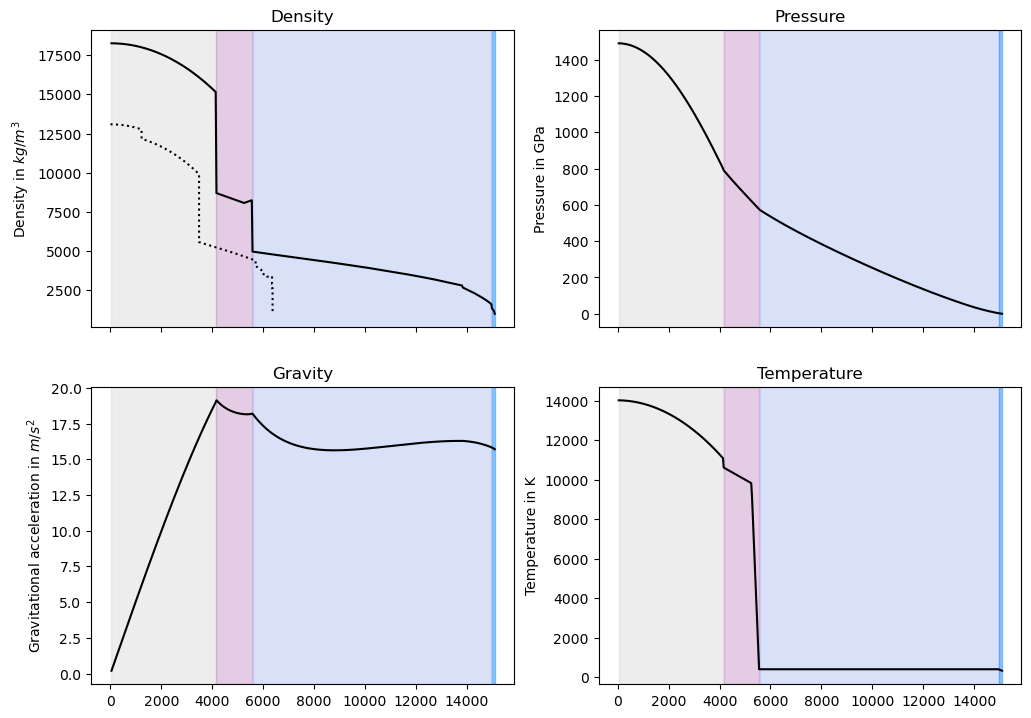

In [46]:
M=8.92; x_Fe_tot=9.50; x_H2O_tot=84.5; T_p=317; P_p=2.56*10**5
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)

print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


In [47]:
NAME = 'K2-18 b'
MASS = 8.92            
RADIUS = 2.37          
RADIUS_ERR = 0.22      
T_SURF = 317.           


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False


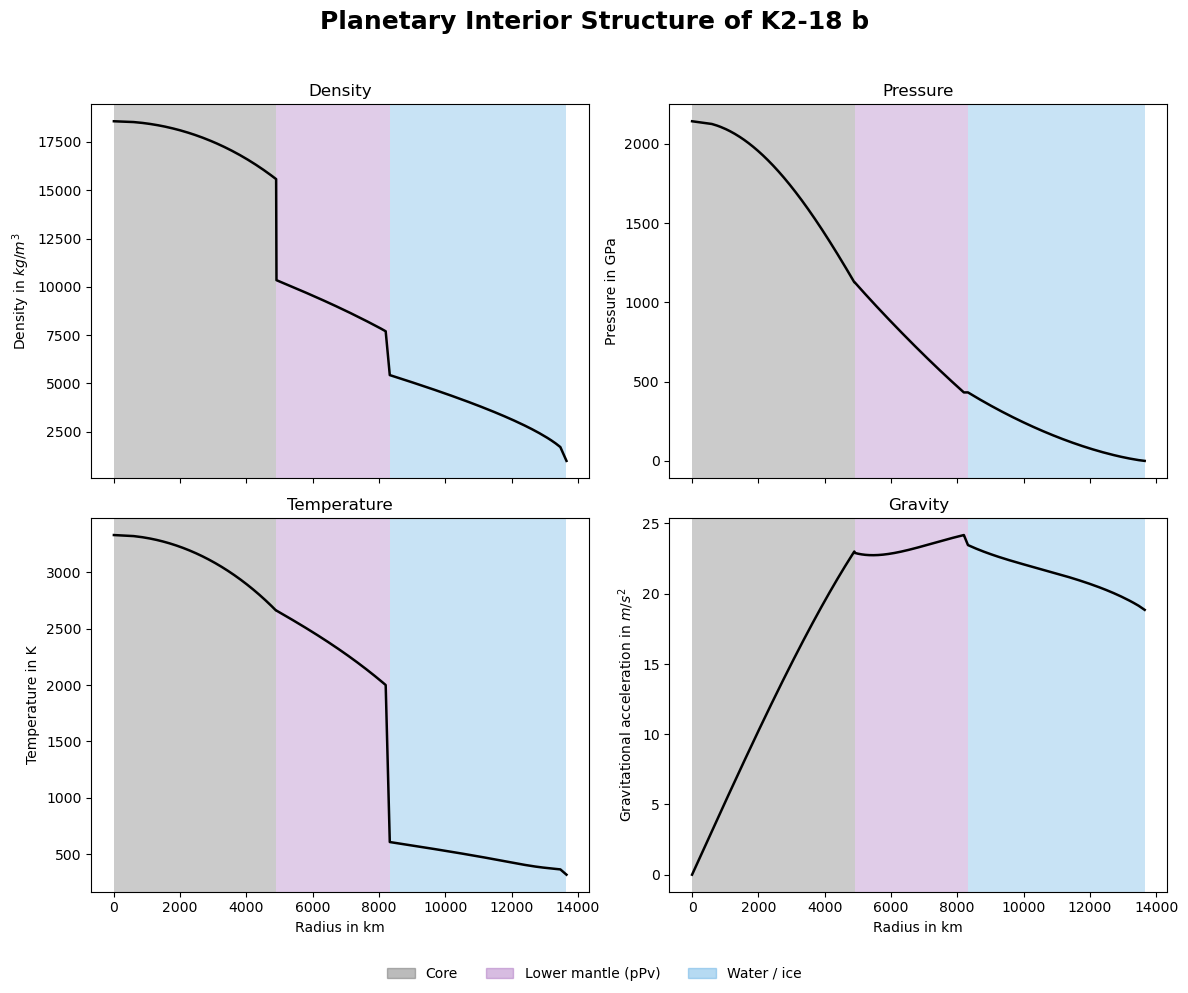

In [48]:
fe_exoplex=0.12; h2o_exoplex=54.17/100; t_pot=2000

Planet = get_planet(MASS, h2o_exoplex, fe_exoplex, t_pot)
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, h2o_exoplex, path=f"Data/{NAME.replace(' ', '_')}_structure.png")

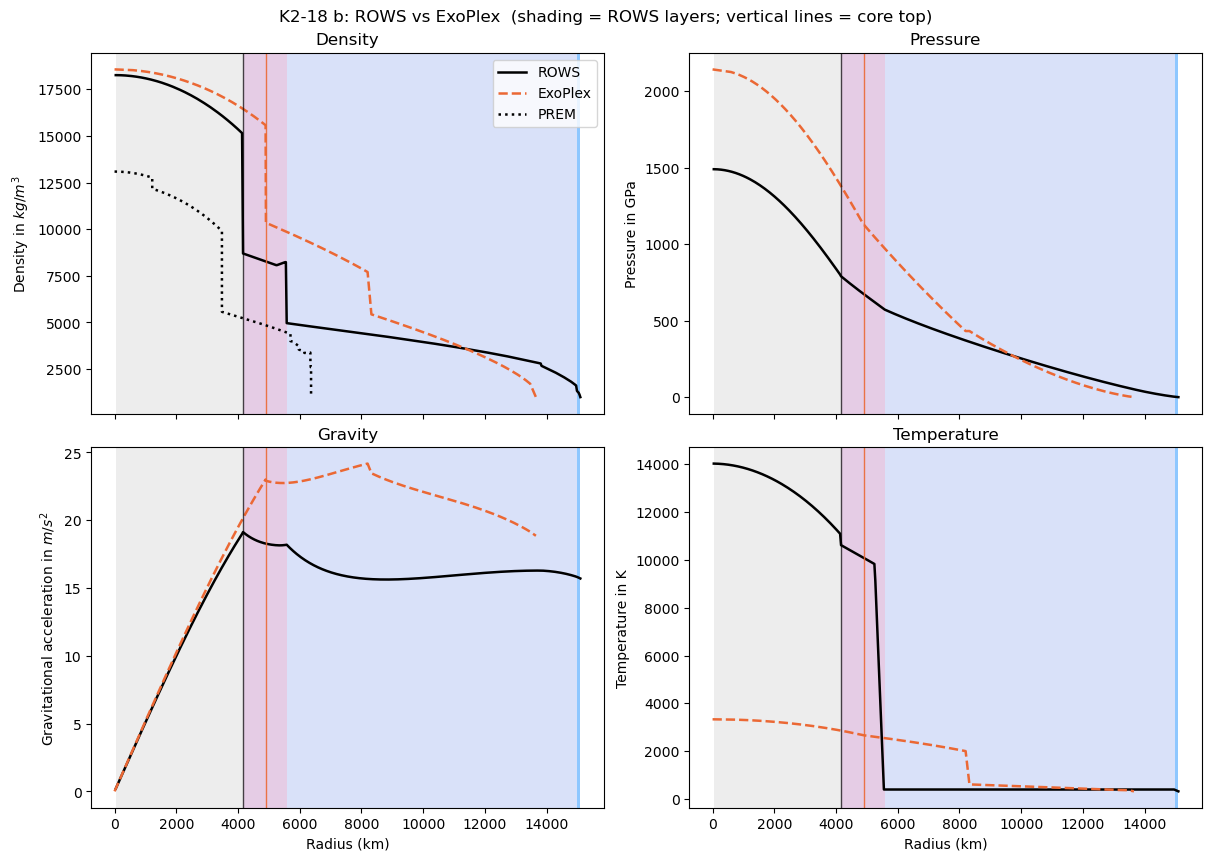

                                    ROWS     ExoPlex
Raio do núcleo (km)                 4164        4905
Raio núcleo / raio planeta         0.276       0.359

Δ raio do núcleo (ExoPlex − ROWS) = +742 km  (+17.8% do valor do ROWS)


In [49]:
mass_obs, temp_obs = MASS, T_SURF                       
FE_ROWS, H2O_ROWS = x_Fe_tot, x_H2O_tot         

(Rp_E, Rc_E, Rm_E, MOI, r_rows, rho_rows, g_rows, P_rows, T_rows,
 alpha, cp, m_rows, elcond, vP, vS, KT, KS, mu, mat) = \
    interior_structure(mass_obs, FE_ROWS, H2O_ROWS, temp_obs, P_p)

r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (np.asarray(a, float) for a in
                                                 (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))
if r_rows[0] > r_rows[-1]:            
    r_rows, rho_rows, g_rows, P_rows, T_rows, mat = (a[::-1] for a in (r_rows, rho_rows, g_rows, P_rows, T_rows, mat))


i_core = np.where((mat == 7) | (mat == 8))[0]
Rcore_rows = r_rows[min(i_core.max() + 1, len(r_rows) - 1)] if len(i_core) else 0.0


r_exo = np.asarray(Planet['radius'], float)
rho_exo = np.asarray(Planet['density'], float)
g_exo = np.asarray(Planet['gravity'], float)
P_exo = np.asarray(Planet['pressure'], float) * 1e5          
T_exo = np.asarray(Planet['temperature'], float)
ok = rho_exo > 0                                             
r_exo, rho_exo, g_exo, P_exo, T_exo = (a[ok] for a in (r_exo, rho_exo, g_exo, P_exo, T_exo))
Rcore_exo = np.asarray(Planet['radius'], float)[num_core_layers]   

km = 1e3
cor_exo = "#eb6834"

camadas = [(mat == 0, 'DodgerBlue', .5), (mat < 0, 'RoyalBlue', .2), (mat == 1, 'brown', .2),
           (mat == 2, 'yellow', .2), (mat == 3, 'orange', .2), (mat == 4, 'red', .2),
           (mat == 5, 'SaddleBrown', .2), (mat == 6, 'purple', .2),
           (mat == 7, 'darkgrey', .2), (mat == 8, 'black', .2)]

fig, ax = plt.subplots(2, 2, sharex=True, figsize=(12, 8.5), constrained_layout=True)
paineis = [(ax[0, 0], "Density", "Density in $kg/m^3$", rho_rows, rho_exo),
           (ax[0, 1], "Pressure", "Pressure in GPa", P_rows / 1e9, P_exo / 1e9),
           (ax[1, 0], "Gravity", "Gravitational acceleration in $m/s^2$", g_rows, g_exo),
           (ax[1, 1], "Temperature", "Temperature in K", T_rows, T_exo)]
for a, titulo, ylabel, y_r, y_e in paineis:
    for cond, cor, alfa in camadas:                       
        idx = np.where(cond)[0]
        if idx.size:
            a.axvspan(r_rows[idx[0]] / km, r_rows[min(idx[-1] + 1, len(r_rows) - 1)] / km,
                      alpha=alfa, color=cor, lw=0)
    a.plot(r_rows / km, y_r, color='black', lw=1.8, label="ROWS")
    a.plot(r_exo / km, y_e, color=cor_exo, lw=1.8, ls='--', label="ExoPlex")
    a.axvline(Rcore_rows / km, color='black', lw=1, alpha=.7)      
    a.axvline(Rcore_exo / km, color=cor_exo, lw=1, alpha=.9)
    a.set_title(titulo)
    a.set_ylabel(ylabel)
ax[0, 0].plot(PREM[:, 0] / km, PREM[:, 1], ':', color='black', lw=1.8, label="PREM")
ax[0, 0].legend(loc='upper right')
for a in ax[1]:
    a.set_xlabel("Radius (km)")
fig.suptitle(f"{NAME}: ROWS vs ExoPlex  (shading = ROWS layers; vertical lines = core top)")
os.makedirs("Data", exist_ok=True)
fig.savefig(f"Data/{NAME.replace(' ', '_')}_ROWS_vs_ExoPlex.png", dpi=200)
plt.show()

dR = Rcore_exo - Rcore_rows
print(f"{'':28s}{'ROWS':>12s}{'ExoPlex':>12s}")
print(f"{'Raio do núcleo (km)':28s}{Rcore_rows / km:12.0f}{Rcore_exo / km:12.0f}")
print(f"{'Raio núcleo / raio planeta':28s}{Rcore_rows / r_rows[-1]:12.3f}{Rcore_exo / r_exo[-1]:12.3f}")
print(f"\nΔ raio do núcleo (ExoPlex − ROWS) = {dR / km:+.0f} km  ({100 * dR / Rcore_rows:+.1f}% do valor do ROWS)")